# SpamJam: modelling

## The problem

GrandPied is a marketing company that relies heavily on email. Employees receive more and more spam, ads and harmful messages, but blocking a legitimate email could mean missing a client inquiry or losing business.

SpamJam helps GrandPied's IT team decide which emails to flag as spam. For each email, the model predicts `is_spam`: 1 for spam, 0 for a legitimate email (ham). This is a binary classification task on the Spambase dataset (UCI, id 94), explored and split in `data_exploration.ipynb`.

## The cost of mistakes

The model can make two kinds of mistakes:
- **False positive:** a legitimate email is flagged as spam. A client email could be missed, which could cost GrandPied business.
- **False negative:** a spam email gets through. It's annoying and a possible risk, but employees can still see and delete it.

For GrandPied, false positives cost more, because the company depends on receiving client emails. So we prefer a model that rarely flags legitimate emails, even if it lets a bit more spam through.

## How this guides our choices

- **Metric:** we focus on **precision** for the spam class (of the emails we flag, how many are really spam), while keeping recall reasonable.
- **Threshold:** instead of the default 0.5, we choose the decision threshold on out-of-fold predictions so that precision stays high.
- **Protocol:** every choice is made on the training set with cross-validation; the test set is used once, at the end.

In [19]:
import sys
sys.path.append("../src")
import yaml
import joblib
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.linear_model import LogisticRegression
from sklearn.preprocessing import StandardScaler
from spamjam import constants

#Load config
with open(constants.CONFIG_PATH, "r", encoding="utf-8") as f:
    config = yaml.safe_load(f)

## **Get paths and random state from config**

In [20]:
random_state = config["random_state"]
processed_dir = constants.PROJECT_ROOT / config["data"]["processed_dir"]
train_filename = config["data"]["train_filename"]
test_filename = config["data"]["test_filename"]

## **Load the SAVED datasets directly**

In [21]:
train_df = joblib.load(processed_dir / train_filename)
test_df = joblib.load(processed_dir / test_filename)

## **Isolate features and target for analysis**

In [22]:
X_train = train_df.drop(columns=['is_spam'])
y_train = train_df['is_spam']

print(f" Loaded Train: {X_train.shape} | Test locked away: {test_df.shape}")

 Loaded Train: (3368, 57) | Test locked away: (842, 58)


## **Scale**

In [23]:
scaler = StandardScaler()
X_train_scaled = scaler.fit_transform(X_train)

## **Fit models**

In [24]:
lasso = LogisticRegression(penalty='l1', solver='liblinear', C=1.0, random_state=random_state)
ridge = LogisticRegression(penalty='l2', solver='liblinear', C=1.0, random_state=random_state)

lasso.fit(X_train_scaled, y_train)
ridge.fit(X_train_scaled, y_train)

,penalty,'l2'
,dual,False
,tol,0.0001
,C,1.0
,fit_intercept,True
,intercept_scaling,1
,class_weight,None
,random_state,42
,solver,'liblinear'
,max_iter,100
,multi_class,'deprecated'


## **Plot of top 20 features coefficients L1 vs L2**

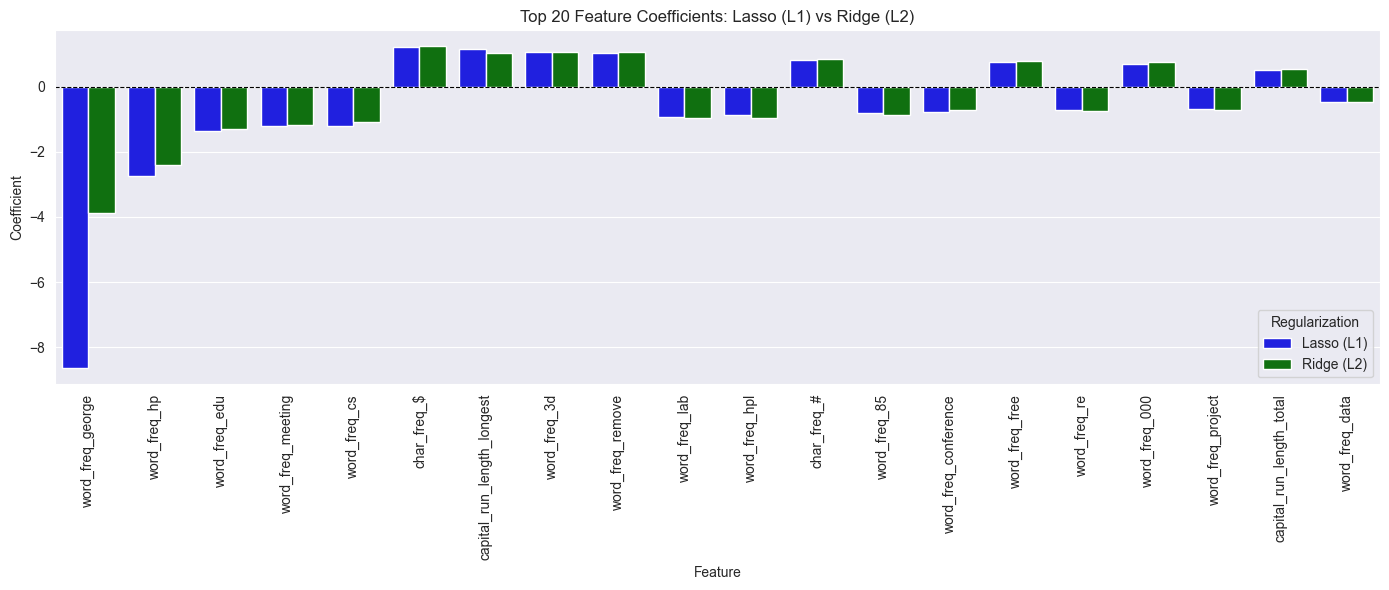

In [25]:
coef_df = pd.DataFrame({
    'Feature': X_train.columns,
    'Lasso (L1)': lasso.coef_[0],
    'Ridge (L2)': ridge.coef_[0]
})
coef_df['Abs_Lasso'] = coef_df['Lasso (L1)'].abs()
coef_df = coef_df.sort_values(by='Abs_Lasso', ascending=False).drop(columns=['Abs_Lasso'])

plot_df = coef_df.head(20).melt(id_vars='Feature', var_name='Regularization', value_name='Coefficient')

plt.figure(figsize=(14, 6))
sns.barplot(data=plot_df, x='Feature', y='Coefficient', hue='Regularization', palette={'Lasso (L1)': 'blue', 'Ridge (L2)': 'green'})
plt.axhline(0, color='black', linewidth=0.8, linestyle='--')
plt.xticks(rotation=90)
plt.title('Top 20 Feature Coefficients: Lasso (L1) vs Ridge (L2)')
plt.tight_layout()
plt.show()